# Chapter 6: Addition Moves, Subtraction Measures

*Math Class Didn't Show Its Work* by Jason Karpeles

**In this notebook you will** see addition as a move along a number line, subtraction as adding an opposite, and a signed answer as something you can always check by adding back.

The code cells are optional reading. You do not need to run anything or follow the code: the results and the pictures are shown right below each cell. If you do want to peek, each code cell redoes the arithmetic one substitution at a time, the way you would on paper.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
%matplotlib inline

# Colors used in every picture
TEAL = "#1f7a7a"
TERRACOTTA = "#c25b3f"
NAVY = "#24344d"
GOLD = "#d9a441"
LIGHT = "#cfd6dd"
INK = "#1d1d1d"

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 11})

def fmt(n):
    """Whole number with commas, like 5,084,000."""
    return f"{int(n):,}"

def signed(n):
    """Show a plus sign on positive numbers: +11, -4, 0."""
    return f"+{n}" if n > 0 else str(n)

def number_line(ax, lo, hi, y=0):
    ax.hlines(y, lo - 0.5, hi + 0.5, color=INK, linewidth=1.5)
    for t in range(lo, hi + 1):
        ax.vlines(t, y - 0.12, y + 0.12, color=INK, linewidth=1)
        ax.text(t, y - 0.45, str(t), ha="center", va="top", fontsize=9, color=TERRACOTTA if t == 0 else INK,
                fontweight="bold" if t == 0 else "normal")
    ax.set_xlim(lo - 1, hi + 1); ax.set_ylim(-1.4, 2.6); ax.axis("off")

def arrow(ax, start, end, y, color, label):
    ax.annotate("", xy=(end, y), xytext=(start, y),
                arrowprops=dict(arrowstyle="->", color=color, linewidth=2.5))
    ax.text((start + end) / 2, y + 0.18, label, ha="center", color=color, fontsize=10)

## Demonstration 1: Start, change, end

**Question in plain words:** A marker starts at $-4$. Where does a positive move leave it: left of zero, on zero, or right of it?

$$-4 + 11 = 7$$

**What the symbols mean:**
- $-4$ is the **start**, a position four steps left of zero.
- The signed **change** says how far to move and which way: plus means right, minus means left.
- The **end** is where the move lands. Zero is just one more mark the move may cross, reach, or never touch.

Addition reads as *start + change = end*.

**Predict first:** from $-4$, a change of $+4$ ends where?

In [2]:
def start_change_end(start, change):
    end = start + change
    shown = f"({change})" if change < 0 else str(change)
    print(f"start + change = end: {start} + {shown} = {end}")
    if start < 0 and end > 0:
        steps_to_zero = -start
        left = change - steps_to_zero
        where = "crosses zero and ends right of it"
        print(f"  {steps_to_zero} steps right reach zero, and {left} more reach {end}: {steps_to_zero} + {left} = {change}")
    elif end == 0:
        where = "lands exactly on zero"
    elif end < 0:
        where = "stays left of zero"
    else:
        where = "ends right of zero"
    direction = "right" if change > 0 else "left"
    print(f"  The move is {abs(change)} steps to the {direction}; it {where}.")
    print(f"  Check by subtraction: {end} - ({start}) = {end} + {-start} = {end - start}")
    print()

start_change_end(-4, 11)
print("Other menu values:\n")
for c in (4, 2, -3):
    start_change_end(-4, c)

start + change = end: -4 + 11 = 7
  4 steps right reach zero, and 7 more reach 7: 4 + 7 = 11
  The move is 11 steps to the right; it crosses zero and ends right of it.
  Check by subtraction: 7 - (-4) = 7 + 4 = 11

Other menu values:

start + change = end: -4 + 4 = 0
  The move is 4 steps to the right; it lands exactly on zero.
  Check by subtraction: 0 - (-4) = 0 + 4 = 4

start + change = end: -4 + 2 = -2
  The move is 2 steps to the right; it stays left of zero.
  Check by subtraction: -2 - (-4) = -2 + 4 = 2

start + change = end: -4 + (-3) = -7
  The move is 3 steps to the left; it stays left of zero.
  Check by subtraction: -7 - (-4) = -7 + 4 = -3



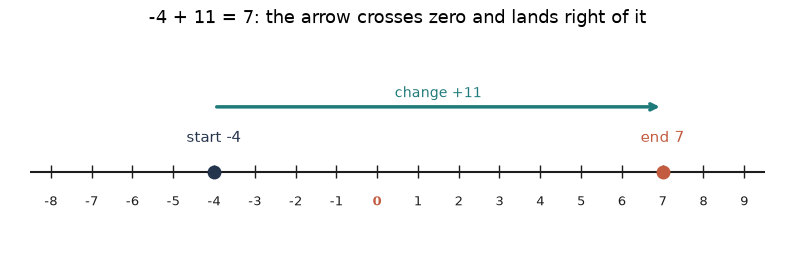

In [3]:
fig, ax = plt.subplots(figsize=(10, 2.8))
number_line(ax, -8, 9)
ax.plot([-4], [0], "o", color=NAVY, markersize=9)
ax.text(-4, 0.55, "start -4", ha="center", color=NAVY)
arrow(ax, -4, 7, 1.2, TEAL, "change +11")
ax.plot([7], [0], "o", color=TERRACOTTA, markersize=9)
ax.text(7, 0.55, "end 7", ha="center", color=TERRACOTTA)
ax.set_title("-4 + 11 = 7: the arrow crosses zero and lands right of it")
plt.show()

**What this shows.** The move is 11 steps to the right. Four steps reach zero and 7 more reach 7: $4 + 7 = 11$. Before you write any signs, name the start, the change and the end. The equation then just records what you already said.

**Where it stops working.** This needs equally spaced marks with right as the positive direction. On a scale drawn with uneven spacing, step counting would no longer match the arithmetic.

## Demonstration 2: Subtract by adding the opposite

**Question in plain words:** Why does $-5 - 3$ move left, while $-5 - (-3)$ moves right?

$$-5 - 3 = -5 + (-3) = -8$$
$$-5 - (-3) = -5 + 3 = -2$$

**What the symbols mean:**
- The first minus sign in each line means *subtract*. A minus sign inside parentheses belongs to the number.
- The opposite of 3 is $-3$, and the opposite of $-3$ is $3$.
- Subtraction keeps the first number and adds the opposite of the second. Removing a leftward move has the effect of a rightward move, so the arrow turns around.

**Predict first:** starting at $-5$ and subtracting $-3$, will the answer be more or less than $-5$?

In [4]:
def subtract(start, sub):
    opp = -sub
    ans = start - sub
    shown = f"({sub})" if sub < 0 else str(sub)
    print(f"{start} - {shown} = {start} + {('(' + str(opp) + ')') if opp < 0 else opp} = {ans}")
    if sub > 0:
        print(f"  Subtracting positive {sub} means {sub} steps left.")
    else:
        print(f"  Subtracting {sub} undoes a leftward move, so travel right: {abs(sub)} steps right.")
    print(f"  Check by adding back what was subtracted: {ans} + {sub} = {ans + sub}" if sub >= 0 else
          f"  Check by adding back what was subtracted: {ans} + ({sub}) = {ans + sub}")
    print()

subtract(-5, 3)
print("Other menu values:\n")
subtract(-5, -3)
subtract(2, 3)
subtract(2, -3)

-5 - 3 = -5 + (-3) = -8
  Subtracting positive 3 means 3 steps left.
  Check by adding back what was subtracted: -8 + 3 = -5

Other menu values:

-5 - (-3) = -5 + 3 = -2
  Subtracting -3 undoes a leftward move, so travel right: 3 steps right.
  Check by adding back what was subtracted: -2 + (-3) = -5

2 - 3 = 2 + (-3) = -1
  Subtracting positive 3 means 3 steps left.
  Check by adding back what was subtracted: -1 + 3 = 2

2 - (-3) = 2 + 3 = 5
  Subtracting -3 undoes a leftward move, so travel right: 3 steps right.
  Check by adding back what was subtracted: 5 + (-3) = 2



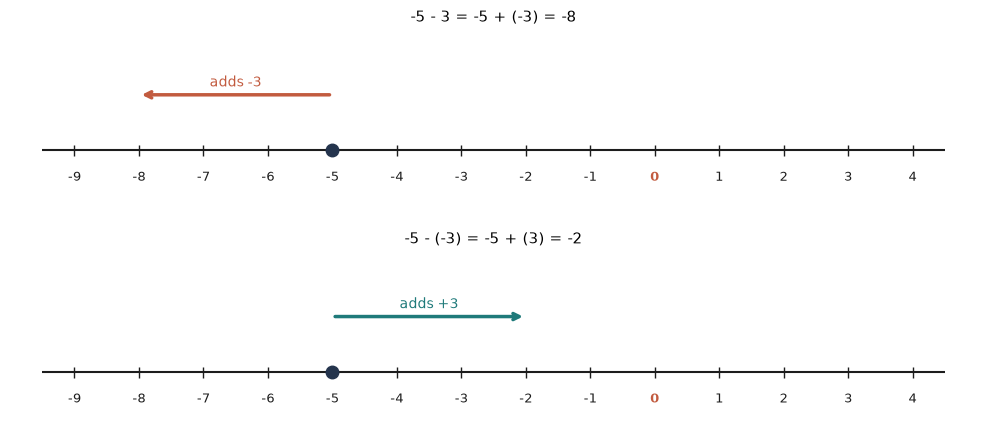

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(10, 4.6))
for ax, (s, sub) in zip(axes, [(-5, 3), (-5, -3)]):
    number_line(ax, -9, 4)
    ans = s - sub
    ax.plot([s], [0], "o", color=NAVY, markersize=9)
    arrow(ax, s, ans, 1.2, TEAL if ans > s else TERRACOTTA, f"adds {signed(-sub)}")
    shown = f"({sub})" if sub < 0 else str(sub)
    ax.set_title(f"{s} - {shown} = {s} + ({-sub}) = {ans}", fontsize=11)
plt.tight_layout(); plt.show()

**What this shows.** $-5 - 3 = -5 + (-3) = -8$: subtracting positive 3 means three steps left. Subtracting $-3$ turns the arrow around, giving $-5 + 3 = -2$. Checking by adding back the number you subtracted returns you to the start: $-8 + 3 = -5$. When two minus signs sit side by side, say both roles aloud: "minus" for the operation, "negative" for the number.

**Where it stops working.** This is for signed numbers on one number line with right as positive. The rule rewrites *subtraction* only. Adding a negative number stays an addition.

## Demonstration 3: Change or distance?

**Question in plain words:** Between $-4$ and $7$, when is the answer $+11$, when $-11$, and when just $11$?

$$7 - (-4) = 7 + 4 = 11$$

**What the symbols mean:**
- **Signed change** is *end - start* and keeps a direction sign.
- **Distance** is how far apart two positions are: always nonnegative, with no direction.
- Reversing start and end reverses the arrow, so the signed change flips sign. A distance bar has no arrowhead, so order does not matter.

**Predict first:** if the marker moves from $7$ back to $-4$, what signed change will you see?

In [6]:
def change_or_distance(start, end, question):
    print(f"Start {start}, end {end}, asking for: {question}")
    if question == "signed change":
        ch = end - start
        print(f"  Signed change is end - start: {end} - ({start}) = {end} + {-start} = {ch}")
        print(f"  Answer: {signed(ch)} ({'rightward' if ch > 0 else 'leftward'})")
        print(f"  Check: {start} + ({ch}) = {start + ch}")
    else:
        d = abs(end - start)
        print(f"  Distance is the size of the gap: |{end} - ({start})| = |{end - start}| = {d}")
        print(f"  Answer: {d}, with no direction")
    print()

change_or_distance(-4, 7, "signed change")
print("Other menu values:\n")
change_or_distance(-4, 7, "distance")
change_or_distance(7, -4, "signed change")
change_or_distance(7, -4, "distance")

Start -4, end 7, asking for: signed change
  Signed change is end - start: 7 - (-4) = 7 + 4 = 11
  Answer: +11 (rightward)
  Check: -4 + (11) = 7

Other menu values:

Start -4, end 7, asking for: distance
  Distance is the size of the gap: |7 - (-4)| = |11| = 11
  Answer: 11, with no direction

Start 7, end -4, asking for: signed change
  Signed change is end - start: -4 - (7) = -4 + -7 = -11
  Answer: -11 (leftward)
  Check: 7 + (-11) = -4

Start 7, end -4, asking for: distance
  Distance is the size of the gap: |-4 - (7)| = |-11| = 11
  Answer: 11, with no direction



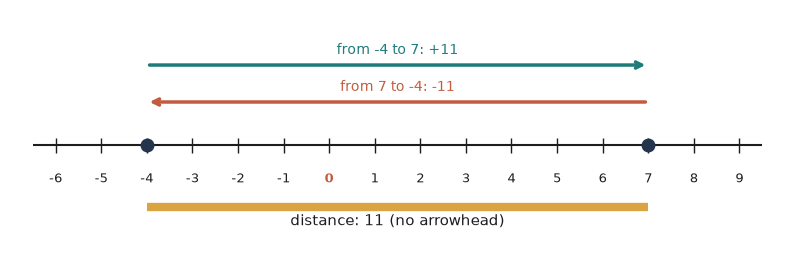

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.2))
number_line(ax, -6, 9)
ax.plot([-4, 7], [0, 0], "o", color=NAVY, markersize=9)
arrow(ax, -4, 7, 1.3, TEAL, "from -4 to 7: +11")
arrow(ax, 7, -4, 0.7, TERRACOTTA, "from 7 to -4: -11")
ax.hlines(-1.0, -4, 7, color=GOLD, linewidth=6)
ax.text(1.5, -1.3, "distance: 11 (no arrowhead)", ha="center", color=INK)
ax.set_ylim(-1.8, 2.2)
plt.show()

**What this shows.** Going from $-4$ to $7$, the signed change is $7 - (-4) = 7 + 4 = +11$, and the sign reports direction (rightward). Going back from $7$ to $-4$ gives $-11$. The distance is 11 either way. Before subtracting, ask which question is being asked: a move with direction, or a separation without it. The word "difference" alone does not say.

**Where it stops working.** This needs two labeled positions on one line with right as positive. If the order of start and end is not stated, a signed change cannot be given.

## Demonstration 4: Crossing zero, checked by addition

**Question in plain words:** How can you tell that $12 - 19$ is $-7$ and not $7$?

$$12 - 19 = -7$$
$$-7 + 19 = 12$$

**What the symbols mean:**
- Subtracting positive 19 means nineteen steps left from 12. Twelve steps reach zero and the rest carry on past it.
- The check adds 19 back to a proposed answer. It must land on 12, so a wrong sign shows up as a missed landing.

**Predict first:** if someone proposes $7$ for $12 - 19$, where will the check land?

In [8]:
def crossing(sub, flip=False):
    ans = 12 - sub
    proposed = -ans if flip else ans
    print(f"12 - {sub} = {ans}")
    if ans < 0:
        print(f"  Twelve of the {sub} leftward steps reach zero; {sub} - 12 = {sub - 12} remain, so the end is {ans}.")
    elif ans == 0:
        print(f"  Twelve leftward steps land exactly on zero.")
    print(f"  Proposed answer: {proposed}" + ("  (0 has no sign to flip, so it is the same answer)" if flip and ans == 0 else ""))
    land = proposed + sub
    print(f"  Check by adding back: ({proposed}) + {sub} = {land}")
    print(f"  Lands on 12? {'yes, so the answer is confirmed' if land == 12 else 'no, so look at the sign first'}")
    print()

crossing(19)
print("Other menu values:\n")
crossing(19, flip=True)
crossing(12)
crossing(12, flip=True)
crossing(5)
crossing(5, flip=True)

12 - 19 = -7
  Twelve of the 19 leftward steps reach zero; 19 - 12 = 7 remain, so the end is -7.
  Proposed answer: -7
  Check by adding back: (-7) + 19 = 12
  Lands on 12? yes, so the answer is confirmed

Other menu values:

12 - 19 = -7
  Twelve of the 19 leftward steps reach zero; 19 - 12 = 7 remain, so the end is -7.
  Proposed answer: 7
  Check by adding back: (7) + 19 = 26
  Lands on 12? no, so look at the sign first

12 - 12 = 0
  Twelve leftward steps land exactly on zero.
  Proposed answer: 0
  Check by adding back: (0) + 12 = 12
  Lands on 12? yes, so the answer is confirmed

12 - 12 = 0
  Twelve leftward steps land exactly on zero.
  Proposed answer: 0  (0 has no sign to flip, so it is the same answer)
  Check by adding back: (0) + 12 = 12
  Lands on 12? yes, so the answer is confirmed

12 - 5 = 7
  Proposed answer: 7
  Check by adding back: (7) + 5 = 12
  Lands on 12? yes, so the answer is confirmed

12 - 5 = 7
  Proposed answer: -7
  Check by adding back: (-7) + 5 = -2
  L

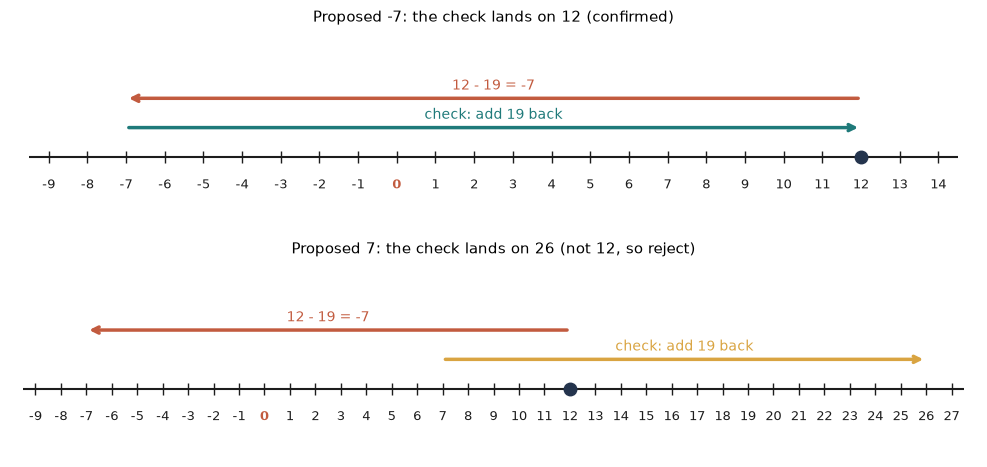

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(10, 4.8))
for ax, prop, title in zip(axes, [-7, 7], ["Proposed -7: the check lands on 12 (confirmed)",
                                           "Proposed 7: the check lands on 26 (not 12, so reject)"]):
    number_line(ax, -9, 27 if prop == 7 else 14)
    ax.plot([12], [0], "o", color=NAVY, markersize=9)
    arrow(ax, 12, -7, 1.2, TERRACOTTA, "12 - 19 = -7")
    arrow(ax, prop, prop + 19, 0.6, TEAL if prop == -7 else GOLD, "check: add 19 back")
    ax.set_title(title, fontsize=11)
plt.tight_layout(); plt.show()

**What this shows.** $12 - 19 = -7$: twelve of the 19 leftward steps reach zero and 7 remain. Adding 19 back must return to the start: $(-7) + 19 = 12$ passes, while the wrong proposal $7 + 19 = 26$ misses. After any subtraction with signs, add the subtracted number back to your answer. If you do not land on the start, look at the sign first.

**Where it stops working.** The check works for signed whole numbers and is exact. It catches a wrong answer but does not tell you which step went wrong.

## Practice

**1.** A marker starts at $-6$ and moves $+9$. Where does it end, and does it cross zero?

<details><summary>Show answer</summary>

-6 + 9 = 3. Six steps reach zero and three more pass it, so it ends at 3, right of zero.
Check: 3 - (-6) = 3 + 6 = 9.

</details>

**2.** What is $8 - (-3)$, and how do you check it?

<details><summary>Show answer</summary>

8 - (-3) = 8 + 3 = 11.
Check: 11 + (-3) = 8.

</details>

**3.** A reading moves from $-3$ units to $5$ units. What are the signed change and the distance?

<details><summary>Show answer</summary>

Signed change: 5 - (-3) = 5 + 3 = +8 units.
Distance: 8 units, with no sign.

</details>

**4.** Using the addition check, is $5 - 13$ equal to $8$ or to $-8$?

<details><summary>Show answer</summary>

Try -8: -8 + 13 = 5, which restores the start.
Try 8: 8 + 13 = 21, which does not.
So 5 - 13 = -8.

</details>